# 04 — Support Vector Regression (SVR)
## Practical ML assignment: predict house price (`price_etb`)

**Goal:** Train and evaluate Support Vector Regression, then compare a baseline SVR with a tuned RBF-kernel SVR.

### Methodology
- Target: `price_etb` (ETB).
- Predictors: numeric columns, excluding the identifier `house_id` and target `price_etb`.
- Split: 80% training / 20% test, `random_state=42`.
- Missing numeric values are imputed using training-set medians.
- Features are standardized inside a pipeline. This is essential for SVR because distances and margins depend on feature scale.
- Hyperparameter tuning uses cross-validation on the training set only; the test set remains untouched until final evaluation.

**Potential leakage note:** `days_on_market` may not be known at the moment a listing price is predicted. This notebook includes it to follow a broad numeric-predictor practical exercise, but for a real-world model predicting price at listing time, remove it from `FEATURES` before splitting and rerun all models consistently.


## 1. Import libraries and load the dataset

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "price_etb"
DATA_FILENAME = "Practical_Dataset for ML.xlsx"

# Supports running from either ML_Course/ or ML_Course/notebooks/.
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd
candidates = [
    Path("data") / DATA_FILENAME,
    Path("ML_Course") / "data" / DATA_FILENAME,
    Path("..") / "data" / DATA_FILENAME,
    Path("..") / ".." / "data" / DATA_FILENAME,  
    Path("ML_Course") / DATA_FILENAME,
    Path("..") / ".." / ".." / "data" / DATA_FILENAME,  
    Path("/mnt/data") / DATA_FILENAME,
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILENAME}. Put it in ML_Course/data/ "
        "or directly inside ML_Course, then rerun this cell."
    )

df = pd.read_excel(DATA_PATH, sheet_name="Data")
print("Loaded:", DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Loaded: ..\..\data\Practical_Dataset for ML.xlsx
Dataset shape: (3000, 17)
Columns: ['house_id', 'size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market', 'price_etb']


,house_id,size_sqm,num_bedrooms,num_bathrooms,floor_level,age_years,renovated,distance_to_bole_km,distance_to_main_road_m,has_garage,parking_spaces,has_garden,security_service,water_supply_hours_per_day,school_rating,days_on_market,price_etb
0,AA-10000,84.8,3,3,0,12,1,9.54,195,1,1,0,1,18.1,4.2,56,4664000
1,AA-10001,142.1,4,3,12,21,0,2.03,119,1,3,0,1,9.1,6.1,19,6209000
2,AA-10002,110.3,3,3,0,6,0,6.96,260,0,0,1,0,24.0,6.7,19,5804000
3,AA-10003,32.0,1,1,11,5,0,7.28,157,0,0,0,0,13.5,4.6,74,1134000
4,AA-10004,61.9,2,1,6,13,0,10.04,153,1,2,0,1,18.1,7.5,12,1810000


In [3]:
def regression_metrics(y_true, y_pred):
    """Return common regression metrics in the target's original units."""
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_train_test(model, X_train, y_train, X_test, y_test):
    """Evaluate an already-fitted model on both train and test data."""
    rows = []
    for split_name, X_part, y_part in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test),
    ]:
        pred = model.predict(X_part)
        row = {"Dataset": split_name}
        row.update(regression_metrics(y_part, pred))
        rows.append(row)
    return pd.DataFrame(rows).set_index("Dataset")

def interpret_metrics(metrics):
    """Print a short interpretation from the model's actual metric values."""
    train = metrics.loc["Train"]
    test = metrics.loc["Test"]
    print(f"Test MAE: {test['MAE']:,.2f} ETB.")
    print(f"Test RMSE: {test['RMSE']:,.2f} ETB.")
    print(f"Test R²: {test['R2']:.4f}.")
    gap = test["RMSE"] - train["RMSE"]
    print(f"Test RMSE minus train RMSE: {gap:,.2f} ETB.")
    if gap > max(0.10 * train["RMSE"], 1):
        print("Interpretation: test error is noticeably higher than train error; check for overfitting.")
    elif gap < -max(0.10 * train["RMSE"], 1):
        print("Interpretation: test error is lower than train error. This can happen with a harder training set or sampling variation; it is not automatically a problem.")
    else:
        print("Interpretation: train and test RMSE are relatively close; check the absolute error size as well.")
    if test["R2"] < 0:
        print("Test R² is negative: on this test set, the model is worse than predicting the test-set mean.")
    else:
        print("Test R² is non-negative: the model improves on the test-set mean baseline under the R² definition.")
    print("Always judge errors against the practical context and compare models on the same test rows.")


## 2. Select features and inspect data

In [4]:
# This workbook's data dictionary marks house_id as an identifier, not a predictor.
# Keep numeric features only for this SVR exercise.
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
FEATURES = [c for c in numeric_columns if c != TARGET]

if TARGET not in df.columns:
    raise ValueError(f"Target column {TARGET!r} was not found.")
if not FEATURES:
    raise ValueError("No numeric predictor columns were found.")

print("Target:", TARGET)
print("Numeric predictors:", FEATURES)
print("Rows:", len(df))
print("Missing values in selected predictors:")
display(df[FEATURES].isna().sum().sort_values(ascending=False))
print("Missing target values:", df[TARGET].isna().sum())


Target: price_etb
Numeric predictors: ['size_sqm', 'num_bedrooms', 'num_bathrooms', 'floor_level', 'age_years', 'renovated', 'distance_to_bole_km', 'distance_to_main_road_m', 'has_garage', 'parking_spaces', 'has_garden', 'security_service', 'water_supply_hours_per_day', 'school_rating', 'days_on_market']
Rows: 3000
Missing values in selected predictors:


water_supply_hours_per_day    63
school_rating                 53
size_sqm                       0
floor_level                    0
age_years                      0
num_bedrooms                   0
num_bathrooms                  0
distance_to_bole_km            0
renovated                      0
distance_to_main_road_m        0
has_garage                     0
has_garden                     0
parking_spaces                 0
security_service               0
days_on_market                 0
dtype: int64

Missing target values: 0


## 3. Split once into training and test sets

The split is performed before fitting any imputer, scaler, or model. `house_id` is excluded because it is an identifier. If notebooks 01 and 02 used a different split seed or filtered rows, match those choices here so the test observations are identical.

In [5]:
model_df = df[FEATURES + [TARGET]].dropna(subset=[TARGET]).copy()
X = model_df[FEATURES]
y = model_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print(f"Total observations: {len(model_df)}")
print(f"Training observations: {len(X_train)} ({len(X_train)/len(model_df):.1%})")
print(f"Test observations: {len(X_test)} ({len(X_test)/len(model_df):.1%})")


Total observations: 3000
Training observations: 2400 (80.0%)
Test observations: 600 (20.0%)


## 4. Build a baseline SVR pipeline

SVR is sensitive to feature scale. For example, `distance_to_main_road_m` may be measured in hundreds of metres, while `renovated` is only 0 or 1. `StandardScaler` standardizes features using training-set means and standard deviations. The pipeline ensures these values are learned from training data only.

The RBF kernel can model nonlinear relationships. Baseline settings are not guaranteed to be optimal.

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

baseline_svr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf", C=1.0, epsilon=0.1, gamma="scale"))
])

baseline_svr.fit(X_train, y_train)
baseline_metrics = evaluate_train_test(
    baseline_svr, X_train, y_train, X_test, y_test
)
print("Baseline SVR metrics:")
display(baseline_metrics.round(4))
interpret_metrics(baseline_metrics)


Baseline SVR metrics:


,MAE,MSE,RMSE,R2
Dataset,,,,
Train,3.129359e+06,2.599002e+13,5.098041e+06,-0.1066
Test,3.338495e+06,3.006847e+13,5.483473e+06,-0.1241


Test MAE: 3,338,494.82 ETB.
Test RMSE: 5,483,472.54 ETB.
Test R²: -0.1241.
Test RMSE minus train RMSE: 385,431.51 ETB.
Interpretation: train and test RMSE are relatively close; check the absolute error size as well.
Test R² is negative: on this test set, the model is worse than predicting the test-set mean.
Always judge errors against the practical context and compare models on the same test rows.


## 5. Tune SVR using training-only cross-validation

Main parameters:
- **C:** penalty for errors; larger values fit training observations more tightly and may overfit.
- **epsilon:** width of the no-penalty tube around the regression function, in target units. Since the target is ETB, use meaningful ETB-scale values.
- **gamma:** controls how local the influence of a training point is for the RBF kernel. Larger gamma can create more flexible fits.

Because the target is in ETB, the epsilon search values below are deliberately expressed in ETB. Grid search can take several minutes depending on your computer. For a faster first run, reduce the grid.

In [7]:
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "svr__C": [100_000, 1_000_000, 10_000_000],
    "svr__epsilon": [10_000, 100_000, 300_000],
    "svr__gamma": ["scale", 0.01, 0.1],
}

svr_search = GridSearchCV(
    estimator=Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf"))
    ]),
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

svr_search.fit(X_train, y_train)

print("Best parameters:", svr_search.best_params_)
print(f"Best mean CV MAE: {-svr_search.best_score_:,.2f} ETB")
tuned_svr = svr_search.best_estimator_


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best parameters: {'svr__C': 10000000, 'svr__epsilon': 100000, 'svr__gamma': 0.01}
Best mean CV MAE: 847,709.00 ETB


## 6. Evaluate the tuned SVR on train and test data

In [8]:
tuned_metrics = evaluate_train_test(
    tuned_svr, X_train, y_train, X_test, y_test
)
print("Tuned SVR metrics:")
display(tuned_metrics.round(4))
interpret_metrics(tuned_metrics)

svr_comparison = pd.concat([
    baseline_metrics.assign(Model="Baseline SVR").reset_index(),
    tuned_metrics.assign(Model="Tuned SVR").reset_index()
], ignore_index=True)

display(
    svr_comparison[["Model", "Dataset", "MAE", "MSE", "RMSE", "R2"]]
    .sort_values(["Model", "Dataset"])
    .round(3)
)


Tuned SVR metrics:


,MAE,MSE,RMSE,R2
Dataset,,,,
Train,787456.5809,1.985306e+12,1.409009e+06,0.9155
Test,918277.4103,3.055094e+12,1.747883e+06,0.8858


Test MAE: 918,277.41 ETB.
Test RMSE: 1,747,882.67 ETB.
Test R²: 0.8858.
Test RMSE minus train RMSE: 338,873.76 ETB.
Interpretation: test error is noticeably higher than train error; check for overfitting.
Test R² is non-negative: the model improves on the test-set mean baseline under the R² definition.
Always judge errors against the practical context and compare models on the same test rows.


,Model,Dataset,MAE,MSE,RMSE,R2
1,Baseline SVR,Test,3338494.823,3.006847e+13,5483472.540,-0.124
0,Baseline SVR,Train,3129358.535,2.599002e+13,5098041.027,-0.107
3,Tuned SVR,Test,918277.410,3.055094e+12,1747882.668,0.886
2,Tuned SVR,Train,787456.581,1.985306e+12,1409008.911,0.915


### Interpreting the results
- Compare **test MAE and RMSE** for the baseline and tuned SVR. Lower is better.
- Check the gap between training and test metrics. Very low training error with much higher test error can indicate overfitting.
- If both errors are high, the model may underfit, the features may be weak, or the search grid may need adjustment.
- Test R² can be negative. That means the model is worse than the test-set mean baseline on this test sample.
- The best CV MAE is calculated from training folds; it is used for tuning. Do not confuse it with the final test MAE.

A tuned model does not have to beat linear regression or Random Forest. Record the actual results and compare all algorithms fairly.

## 7. Plot actual versus predicted prices

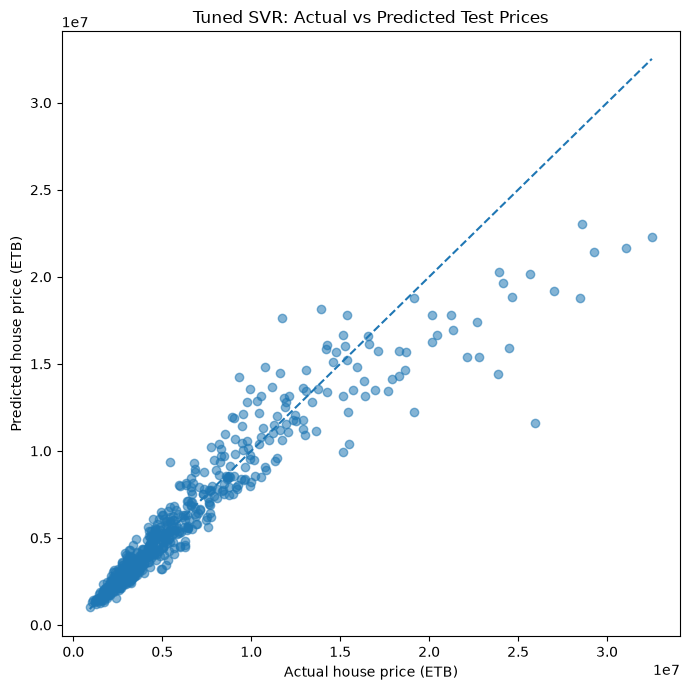

In [9]:
test_predictions = tuned_svr.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, test_predictions, alpha=0.55)
low = min(float(y_test.min()), float(test_predictions.min()))
high = max(float(y_test.max()), float(test_predictions.max()))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual house price (ETB)")
plt.ylabel("Predicted house price (ETB)")
plt.title("Tuned SVR: Actual vs Predicted Test Prices")
plt.tight_layout()
plt.show()


## 8. Residual analysis

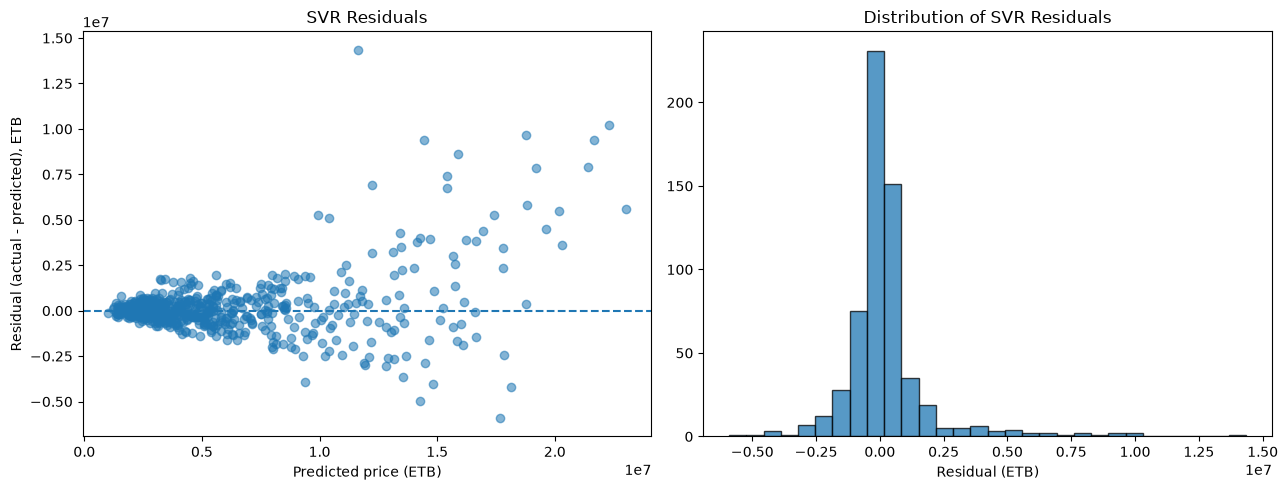

Positive residual: model underpredicted that observation.
Negative residual: model overpredicted that observation.
Look for patterns, skew, or a few very large residuals rather than relying on one plot alone.


In [10]:
residuals = y_test.to_numpy() - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(test_predictions, residuals, alpha=0.55)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted price (ETB)")
axes[0].set_ylabel("Residual (actual - predicted), ETB")
axes[0].set_title("SVR Residuals")

axes[1].hist(residuals, bins=30, edgecolor='black', alpha=0.75)
axes[1].set_xlabel("Residual (ETB)")
axes[1].set_title("Distribution of SVR Residuals")
plt.tight_layout()
plt.show()

print("Positive residual: model underpredicted that observation.")
print("Negative residual: model overpredicted that observation.")
print("Look for patterns, skew, or a few very large residuals rather than relying on one plot alone.")


## 9. Save metrics and tuning results

In [11]:
metrics_dir = PROJECT_ROOT / "outputs" / "metrics"
plots_dir = PROJECT_ROOT / "outputs" / "plots"
metrics_dir.mkdir(parents=True, exist_ok=True)
plots_dir.mkdir(parents=True, exist_ok=True)

baseline_metrics.assign(Model="Baseline SVR").to_csv(
    metrics_dir / "04_svr_baseline_metrics.csv"
)
tuned_metrics.assign(Model="Tuned SVR").to_csv(
    metrics_dir / "04_svr_tuned_metrics.csv"
)
svr_comparison.to_csv(
    metrics_dir / "04_svr_comparison.csv", index=False
)
pd.DataFrame(svr_search.cv_results_).to_csv(
    metrics_dir / "04_svr_grid_search_results.csv", index=False
)
print("Saved SVR metrics and grid-search results to:", metrics_dir)


Saved SVR metrics and grid-search results to: C:\Users\hp\ML_Course\Notebooks\Regression\outputs\metrics


## 10. Conclusion template

After running the notebook, report:
1. Baseline SVR test MAE, RMSE, and R².
2. Best cross-validation MAE and the selected hyperparameters.
3. Tuned SVR test MAE, RMSE, and R².
4. Whether tuning improved test performance.
5. What the train/test gap suggests about generalization.
6. Whether SVR performs better or worse than SLR/MLR on the same test observations.
7. Any limitations, including potential leakage from `days_on_market`.

Use actual output values. Do not invent or copy example metrics.